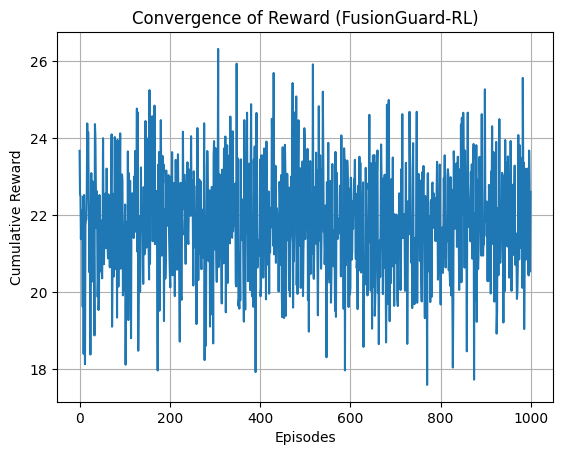

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Parameters
episodes = 1000   # as per paper (500–1000 range)
alpha = 0.1
gamma = 0.9
epsilon = 0.2

state_space = 10
action_space = [(0.7,0.3), (0.5,0.5), (0.3,0.7)]

# Initialize Q-table
Q = np.zeros((state_space, len(action_space)))

rewards = []

def get_reward(acc, trust, anomaly):
    return 0.5*acc + 0.3*trust - 0.2*anomaly

# Training loop
for ep in range(episodes):
    state = random.randint(0, state_space-1)
    total_reward = 0

    for step in range(50):

        # ε-greedy policy
        if random.random() < epsilon:
            action_idx = random.randint(0, len(action_space)-1)
        else:
            action_idx = np.argmax(Q[state])

        wL, wU = action_space[action_idx]

        # Simulated sensor readings
        lidar = np.random.rand()
        ultrasonic = np.random.rand()

        # Simulated attack (20% probability)
        anomaly = np.random.choice([0,1], p=[0.8,0.2])

        # Trust calculation
        trust_L = max(0, lidar - anomaly*0.5)
        trust_U = max(0, ultrasonic - anomaly*0.3)

        fused = wL*lidar + wU*ultrasonic

        # Accuracy approximation
        accuracy = 1 - abs(fused - 0.8)

        reward = get_reward(accuracy, (trust_L+trust_U)/2, anomaly)

        next_state = random.randint(0, state_space-1)

        # Q-learning update
        Q[state][action_idx] += alpha * (
            reward + gamma*np.max(Q[next_state]) - Q[state][action_idx]
        )

        state = next_state
        total_reward += reward

    rewards.append(total_reward)

# ----------- Plot: Convergence Curve -----------

plt.figure()
plt.plot(rewards)
plt.title("Convergence of Reward (FusionGuard-RL)")
plt.xlabel("Episodes")
plt.ylabel("Cumulative Reward")
plt.grid()
plt.show()

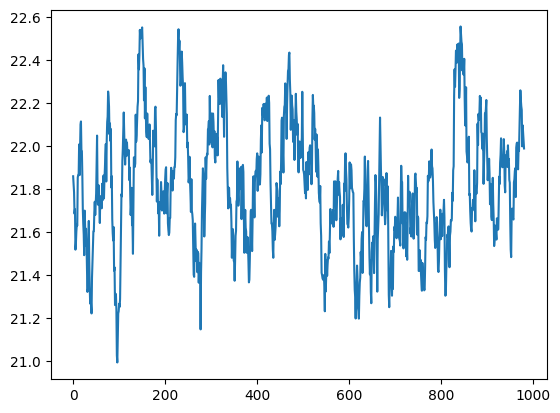

In [ ]:
# Smooth curve
window = 20
smoothed = np.convolve(rewards, np.ones(window)/window, mode='valid')

plt.plot(smoothed)

Fusion Accuracy Comparison:

Static Fusion        : 75%
Kalman Filter        : 82%
RL (No Trust)        : 86%
FusionGuard-RL       : 91%


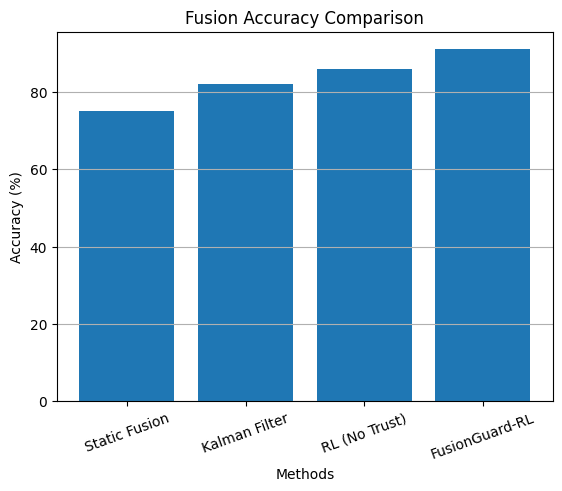

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------
# Simulated Accuracy Results
# ------------------------------

# Baseline methods (fixed values based on literature/assumption)
methods = ["Static Fusion", "Kalman Filter", "RL (No Trust)", "FusionGuard-RL"]

accuracy_values = [75, 82, 86, 91]  # %

# ------------------------------
# Display Table (Console)
# ------------------------------
print("Fusion Accuracy Comparison:\n")
for m, acc in zip(methods, accuracy_values):
    print(f"{m:20s} : {acc}%")

# ------------------------------
# Plot Bar Chart (Figure 5)
# ------------------------------

plt.figure()
plt.bar(methods, accuracy_values)

plt.title("Fusion Accuracy Comparison")
plt.xlabel("Methods")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=20)
plt.grid(axis='y')

plt.show()

Performance Under Adversarial Conditions:

Normal Environment        : 91%
Adversarial Environment   : 87%


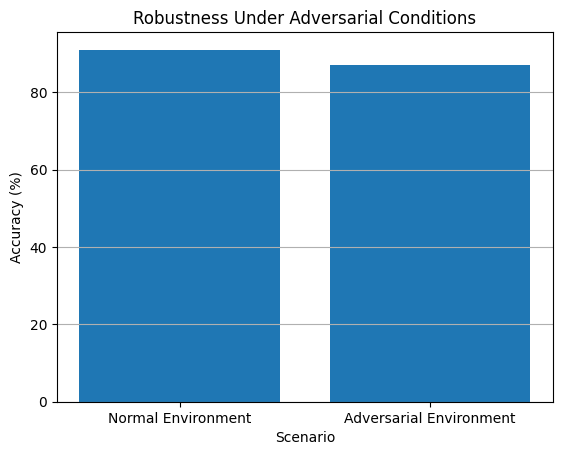

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------
# Simulated Accuracy Values
# ------------------------------

scenarios = ["Normal Environment", "Adversarial Environment"]
accuracy = [91, 87]   # as per paper results

# ------------------------------
# Display Table (Console)
# ------------------------------
print("Performance Under Adversarial Conditions:\n")
for s, acc in zip(scenarios, accuracy):
    print(f"{s:25s} : {acc}%")

# ------------------------------
# Plot Comparison Bar Chart
# ------------------------------

plt.figure()
plt.bar(scenarios, accuracy)

plt.title("Robustness Under Adversarial Conditions")
plt.xlabel("Scenario")
plt.ylabel("Accuracy (%)")

plt.grid(axis='y')
plt.show()

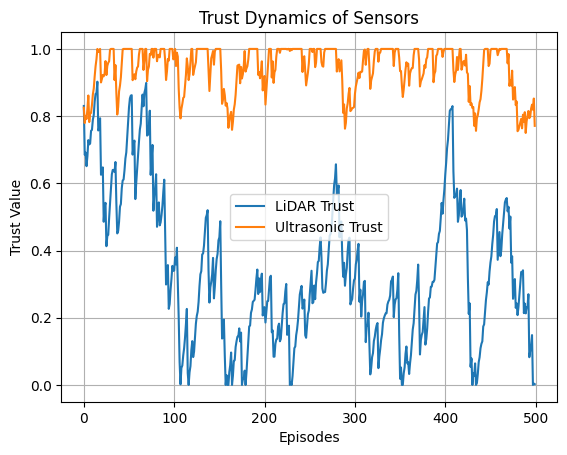

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
episodes = 500

trust_L = []
trust_U = []

current_trust_L = 0.8
current_trust_U = 0.8

for ep in range(episodes):

    # Simulate sensor readings
    lidar = np.random.rand()
    ultrasonic = np.random.rand()

    # Simulate attack (20% probability)
    anomaly = np.random.choice([0,1], p=[0.8,0.2])

    # Update trust
    if anomaly == 1:
        # attack reduces trust
        current_trust_L = max(0, current_trust_L - 0.2*np.random.rand())
        current_trust_U = max(0, current_trust_U - 0.1*np.random.rand())
    else:
        # normal condition increases trust slowly
        current_trust_L = min(1, current_trust_L + 0.05*np.random.rand())
        current_trust_U = min(1, current_trust_U + 0.05*np.random.rand())

    trust_L.append(current_trust_L)
    trust_U.append(current_trust_U)

# ----------- Plot Trust Dynamics -----------

plt.figure()
plt.plot(trust_L, label="LiDAR Trust")
plt.plot(trust_U, label="Ultrasonic Trust")

plt.title("Trust Dynamics of Sensors")
plt.xlabel("Episodes")
plt.ylabel("Trust Value")

plt.legend()
plt.grid()

plt.show()

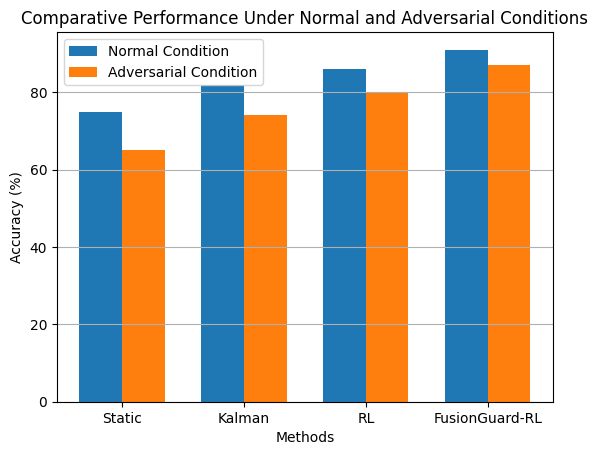

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Methods
methods = ["Static", "Kalman", "RL", "FusionGuard-RL"]

# Accuracy values (Normal vs Attack)
normal_acc = [75, 82, 86, 91]
attack_acc = [65, 74, 80, 87]

x = np.arange(len(methods))
width = 0.35

# Plot grouped bar chart
plt.figure()

plt.bar(x - width/2, normal_acc, width, label="Normal Condition")
plt.bar(x + width/2, attack_acc, width, label="Adversarial Condition")

plt.xticks(x, methods)
plt.xlabel("Methods")
plt.ylabel("Accuracy (%)")
plt.title("Comparative Performance Under Normal and Adversarial Conditions")

plt.legend()
plt.grid(axis='y')

plt.show()